# GridQ: QAOA load balancing for a rural microgrid
**QFF 2026 Quantum for Humanity · Climate track.** All data is synthetic (`data/villages/`).

Every hour, the village's demand minus solar and wind leaves a **shortfall**. The operator must choose which flexible
**providers** (batteries, diesel gensets, demand response) to switch on to cover it **at the lowest cost**.
With *n* providers there are 2ⁿ on/off combinations: one qubit per provider for QAOA.

Run the cells top to bottom. **Change the village or hour in cell 1.**

## 1 · Choose the village and load its data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from gridq import build_qubo, dispatch_metrics, cost_saved_pct, repair
from gridq.data import load_village
from gridq.metrics import naive_policy_cost

# ---- pick ONE village (uncomment the one you want) -------------------------
# VILLAGE = "village_n6_s0"     # 6 providers  (the one run on real IBM hardware)
VILLAGE = "village_n8_s0"       # 8 providers  (main demo)
# VILLAGE = "village_n8_s1"     # 8 providers, different mix
# VILLAGE = "village_n10_s0"    # 10 providers
# VILLAGE = "village_n12_s0"    # 12 providers

HOUR = None   # None = the hour with the biggest shortfall, or set e.g. HOUR = 19

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
village = load_village(ROOT / "data" / "villages" / VILLAGE)
balance = village.hourly_balance()
if HOUR is None:
    HOUR = int(balance.loc[balance.shortfall_kw.idxmax(), "hour"])
grid = village.microgrid(HOUR)          # the optimisation problem for that hour
qubo = build_qubo(grid)                 # the same QUBO is used by every solver
print(f"{VILLAGE}: {village.n} providers ({village.providers.capacity_kw.sum():.1f} kW), "
      f"solving {HOUR:02d}:00 with a shortfall of {grid.deficit} kW, {2 ** village.n:,} combinations")
print(village.meta.get("note", ""))

village_n8_s0: 8 providers (39.2 kW), solving 19:00 with a shortfall of 17.6 kW, 256 combinations
Synthetic data generated by gridq.data.make_village. Edit the CSVs to use your own figures.


## 2 · Village demand and the hourly shortfall
Shortfall = demand − solar − wind (`forecast.csv`). Every hour with a shortfall is one optimisation.

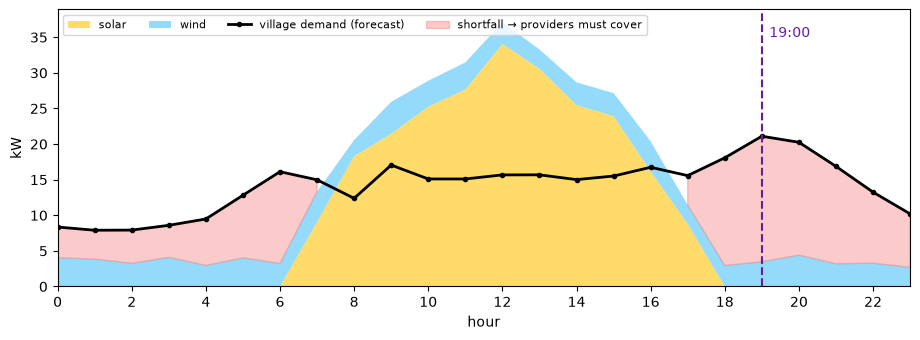

19:00  demand 21.1 − solar 0.0 − wind 3.47 = shortfall 17.63 kW
Hours with a shortfall: 15/24 · peak 17.6 kW · 131 kWh per day


,hour,demand_kw,solar_kw,wind_kw,shortfall_kw
0,0,8.35,0.00,4.04,4.31
1,1,7.90,0.00,3.85,4.05
2,2,7.92,0.00,3.25,4.67
3,3,8.59,0.00,4.10,4.49
4,4,9.48,0.00,2.96,6.52
5,5,12.81,0.00,4.03,8.78
6,6,16.12,0.00,3.23,12.89
7,7,14.98,9.06,4.27,1.65
8,8,12.38,18.31,2.26,0.00
9,9,17.05,21.43,4.50,0.00


In [2]:
b = balance
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.stackplot(b.hour, b.solar_kw, b.wind_kw, labels=["solar", "wind"], colors=["#ffd54f", "#81d4fa"], alpha=0.85)
ax.plot(b.hour, b.demand_kw, "k-o", ms=3, lw=2, label="village demand (forecast)")
ax.fill_between(b.hour, b.renewables_kw, b.demand_kw, where=b.shortfall_kw > 0, color="#ef5350", alpha=0.3,
                label="shortfall → providers must cover")
ax.axvline(HOUR, color="#6a1b9a", ls="--"); ax.text(HOUR + 0.2, ax.get_ylim()[1] * 0.9, f"{HOUR:02d}:00", color="#6a1b9a")
ax.set(xlabel="hour", ylabel="kW", xticks=range(0, 24, 2), xlim=(0, 23)); ax.legend(fontsize=8, ncol=4, loc="upper left")
plt.show()
r = b.set_index("hour").loc[HOUR]
print(f"{HOUR:02d}:00  demand {r.demand_kw} − solar {r.solar_kw} − wind {r.wind_kw} = shortfall {r.shortfall_kw} kW")
print(f"Hours with a shortfall: {int(b.dispatch_needed.sum())}/24 · peak {b.shortfall_kw.max():.1f} kW · "
      f"{b.shortfall_kw.clip(lower=0).sum():.0f} kWh per day")
b.assign(shortfall_kw=b.shortfall_kw.clip(lower=0))[["hour", "demand_kw", "solar_kw", "wind_kw", "shortfall_kw"]]

## 3 · Providers that can cover the shortfall
All providers feed one shared village pool, so any of them can serve the shortfall. Demand response adds power by cutting a site's own use.

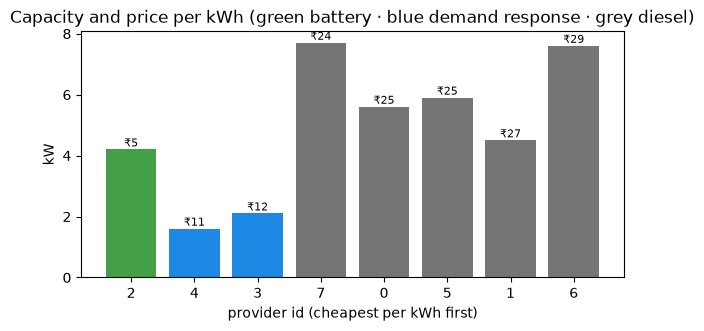

Total capacity 39.2 kW for a 17.6 kW shortfall · diesel-first (status quo) would cost ₹489


,provider_id,site_name,site_type,provider_type,capacity_kw,price_inr_per_kwh,cost_if_on_1h_inr
0,0,Household 0,household,diesel,5.6,24.857,139.2
1,1,Household 1,household,diesel,4.5,26.578,119.6
2,2,School 2,school,battery,4.2,4.976,20.9
3,3,Clinic 3,clinic,demand_response,2.1,12.381,26.0
4,4,Household 4,household,demand_response,1.6,11.375,18.2
5,5,Cold Store 5,cold_store,diesel,5.9,25.136,148.3
6,6,Water Pump 6,water_pump,diesel,7.6,29.118,221.3
7,7,Household 7,household,diesel,7.7,23.818,183.4


In [3]:
p = village.providers.assign(cost_if_on_1h_inr=(village.providers.capacity_kw * village.providers.price_inr_per_kwh).round(1))
colours = {"battery": "#43a047", "demand_response": "#1e88e5", "diesel": "#757575"}
ps = p.sort_values("price_inr_per_kwh").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(ps)), ps.capacity_kw, color=[colours[t] for t in ps.provider_type])
for k, row in ps.iterrows():
    ax.text(k, row.capacity_kw + 0.1, f"₹{row.price_inr_per_kwh:.0f}", ha="center", fontsize=8)
ax.set_xticks(range(len(ps)), ps.provider_id); ax.set(xlabel="provider id (cheapest per kWh first)", ylabel="kW",
       title="Capacity and price per kWh (green battery · blue demand response · grey diesel)")
plt.show()
print(f"Total capacity {p.capacity_kw.sum():.1f} kW for a {grid.deficit} kW shortfall · "
      f"diesel-first (status quo) would cost ₹{naive_policy_cost(grid):.0f}")
p

## 4 · QAOA (quantum)
The circuit has one qubit per provider. COBYLA tunes the angles (CVaR objective), then the circuit is sampled on a simulator and every sample is repaired and scored. **Change the backend below.**

QAOA (ideal, p=3, 1024 shots): providers [0, 1, 2, 3, 4] · 18.0 kW for 17.6 kW · ₹323.9 · 0.8 s
P(optimal) per shot 0.010 = 2.5× random guessing · circuit 8 qubits, 2-qubit depth 58


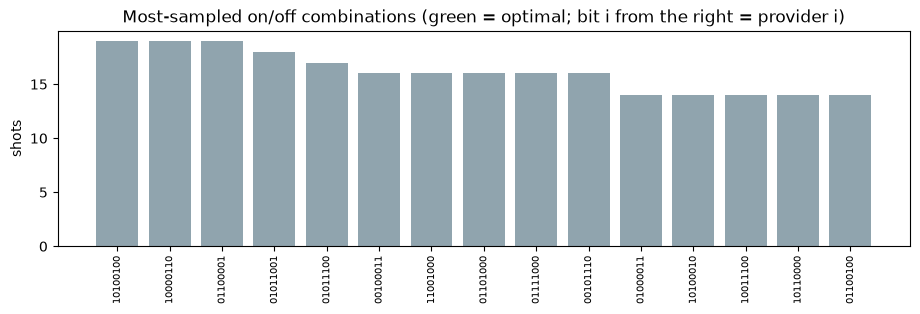

In [4]:
import time
from gridq import solve_qaoa
from gridq.hardware import backend_pass_manager, fake_backend, noisy_sampler

REPS, SHOTS = 3, 1024              # QAOA layers p and shots

# ---- pick ONE backend --------------------------------------------------------
BACKEND = "ideal"                  # perfect, error-free quantum simulator
# BACKEND = "noisy"                # simulator with the real IBM Heron error model (FakeFez)

sampler = pm = None
if BACKEND == "noisy":
    fb = fake_backend(); sampler, pm = noisy_sampler(fb, seed=0), backend_pass_manager(fb)
t0 = time.perf_counter()
qaoa = solve_qaoa(qubo, reps=REPS, shots=SHOTS, sampler=sampler, pass_manager=pm, backend_name=BACKEND)
qaoa_time = time.perf_counter() - t0
x_qaoa = repair(grid, qaoa.repaired_x)
m = dispatch_metrics(grid, x_qaoa)
print(f"QAOA ({BACKEND}, p={REPS}, {SHOTS} shots): providers {np.flatnonzero(x_qaoa).tolist()} · "
      f"{m['supplied_kw']} kW for {grid.deficit} kW · ₹{m['cost_inr']} · {qaoa_time:.1f} s")
print(f"P(optimal) per shot {qaoa.p_optimal:.3f} = {qaoa.enrichment:.1f}× random guessing · "
      f"circuit {grid.n} qubits, 2-qubit depth {qaoa.circuit_stats['two_qubit_depth']}")
top = sorted(qaoa.counts.items(), key=lambda kv: -kv[1])[:15]
from gridq import constrained_optimum
e_opt = qubo.energy(constrained_optimum(qubo).x)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(len(top)), [c for _, c in top],
       color=["#2e7d32" if np.isclose(qubo.energy(np.array([int(ch) for ch in reversed(k)])), e_opt) else "#90a4ae" for k, _ in top])
ax.set_xticks(range(len(top)), [k for k, _ in top], rotation=90, fontsize=7)
ax.set(ylabel="shots", title="Most-sampled on/off combinations (green = optimal; bit i from the right = provider i)")
plt.show()

## 5 · Classical solver to compare against
Brute force (exact) is the default: it checks every combination and gives the true optimum. **Uncomment another solver to compare.**

In [5]:
from gridq import constrained_optimum, simulated_annealing, greedy_operator, greedy_descent, random_sampling

# ---- pick ONE classical solver ------------------------------------------------
SOLVER, solve = "Exact (brute force)", lambda: constrained_optimum(qubo).x
# SOLVER, solve = "Simulated annealing", lambda: simulated_annealing(qubo, sweeps=500, restarts=5).x
# SOLVER, solve = "Greedy (cheapest per kW)", lambda: greedy_operator(qubo).x
# SOLVER, solve = "Greedy descent (QUBO)", lambda: greedy_descent(qubo).x
# SOLVER, solve = "Random sampling (control)", lambda: random_sampling(qubo, shots=SHOTS, seed=0).x

t0 = time.perf_counter(); x_cl = repair(grid, solve()); cl_time = time.perf_counter() - t0
exact = constrained_optimum(qubo).x
rows = []
for name, x, t in (("QAOA (" + BACKEND + ")", x_qaoa, qaoa_time), (SOLVER, x_cl, cl_time)):
    mm = dispatch_metrics(grid, x)
    rows.append({"solver": name, "providers on": ", ".join(map(str, np.flatnonzero(x))),
                 "supplied kW": mm["supplied_kw"], "cost ₹": mm["cost_inr"],
                 "gap to optimum ₹": round(float(grid.cost @ x - grid.cost @ exact), 1),
                 "optimal?": "✅" if np.array_equal(x, exact) else "❌",
                 "saved vs diesel-first %": cost_saved_pct(grid, x), "runtime ms": round(1000 * t, 1)})
pd.DataFrame(rows)

,solver,providers on,supplied kW,cost ₹,gap to optimum ₹,optimal?,saved vs diesel-first %,runtime ms
0,QAOA (ideal),"0, 1, 2, 3, 4",18.0,323.9,0.0,✅,33.8,804.3
1,Exact (brute force),"0, 1, 2, 3, 4",18.0,323.9,0.0,✅,33.8,0.2


## 6 · Real IBM quantum hardware
By default this shows the **saved** run on IBM `ibm_kingston` (`results/hardware_*.json`, 6 providers = `village_n6_s0` at 19:00),
re-scored against the ideal simulator, the noise model and random guessing.

To submit a **new** job for the village and hour chosen in cell 1, fill in `.env` (README §6.4) and uncomment the
`LIVE` block. It uses IBM Quantum credits, and the queue can take seconds to hours.

ibm_kingston · 6 providers · shortfall 11.6 kW · p=2 · 4096 shots · submitted 2026-11-26 12:27:08
Exact optimum: providers [2, 3, 4] · 12.0 kW · ₹61.5


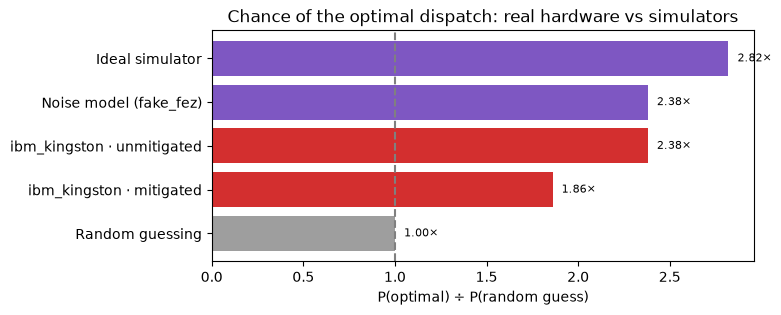

,setting,kind,providers on,cost ₹,optimal?,P(optimal),enrichment ×,job_id
0,Ideal simulator,simulator,"2, 3, 4",61.5,✅,0.0441,2.82,
1,Noise model (fake_fez),simulator,"2, 3, 4",61.5,✅,0.0371,2.38,
2,ibm_kingston · unmitigated,hardware,"2, 3, 4",61.5,✅,0.0371,2.38,dc3tgfds2omc738e88hg
3,ibm_kingston · mitigated,hardware,"2, 3, 4",61.5,✅,0.0291,1.86,dc3tgh6q4uuc73a7l03g
4,Random guessing,baseline,"2, 3, 4",61.5,✅,0.0156,1.00,


In [6]:
from gridq.hardware import score_hardware_run

# ---- A) saved hardware run (default, free) ----------------------------------
HW_FILE = ROOT / "results" / "hardware_ibm_kingston_n6_p2_s0.json"
hw = score_hardware_run(HW_FILE)
od = hw["optimal_dispatch"]
print(f"{hw['backend']} · {hw['n']} providers · shortfall {hw['deficit_kw']} kW · p={hw['reps']} · {hw['shots']} shots · "
      f"submitted {hw['submitted_at']}")
print(f"Exact optimum: providers {hw['optimal_providers']} · {od['supplied_kw']} kW · ₹{od['cost_inr']}")
res = pd.DataFrame(hw["rows"])
res = res.assign(**{"enrichment ×": res.enrichment.round(2), "P(optimal)": res.p_optimal.round(4),
                    "providers on": res.providers_on.apply(lambda v: ", ".join(map(str, v))),
                    "cost ₹": res.cost_inr.round(1), "optimal?": np.where(res.found_optimal, "✅", "❌")})
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(res.setting, res["enrichment ×"],
        color=["#d32f2f" if k == "hardware" else "#9e9e9e" if k == "baseline" else "#7e57c2" for k in res.kind])
for i, v in enumerate(res["enrichment ×"]):
    ax.text(v + 0.05, i, f"{v:.2f}×", va="center", fontsize=8)
ax.invert_yaxis(); ax.axvline(1, ls="--", c="grey"); ax.set(xlabel="P(optimal) ÷ P(random guess)",
       title="Chance of the optimal dispatch: real hardware vs simulators")
plt.show()
display(res[["setting", "kind", "providers on", "cost ₹", "optimal?", "P(optimal)", "enrichment ×", "job_id"]])

# ---- B) LIVE run on real hardware (uses credits): uncomment to submit -------------
# from gridq.hardware import run_qaoa_on_hardware
# live = run_qaoa_on_hardware(grid, reps=2, shots=4096, mitigate=False)
# xl = repair(grid, np.array(live["x"], dtype=np.int8)); ml = dispatch_metrics(grid, xl)
# print(f"LIVE on {live['backend']} · job {live['job_id']} · {live['queue_and_run_s']:.0f} s · "
#       f"providers {np.flatnonzero(xl).tolist()} · ₹{ml['cost_inr']} · optimal: {np.array_equal(xl, exact)} · "
#       f"{live['enrichment']:.2f}× random guessing")